# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# If these packages are missing, install them once in your environment:
# %pip install pandas numpy matplotlib scipy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)

# This works from the repo root, the exercise folder, or here in ChatGPT.
candidates = [
    Path("../data/cars.csv"),
    Path("data/cars.csv"),
    Path("Week-05-Business-Stats-Analytics/data/cars.csv"),
    Path("cars.csv"),
    Path("/mnt/data/cars.csv"),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Put cars.csv in the Week-05 data folder.")

df = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Rows and columns:", df.shape)
display(df.head())

Loaded: ../data/cars.csv
Rows and columns: (11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [3]:
# Look for data issues before cleaning anything.
print("Shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing values:")
print(df.isna().sum().to_string())

print("\nMost frequent prices:")
print(df["MSRP"].value_counts().head(5).to_string())
print("\nRows priced at exactly $2,000:", (df["MSRP"] == 2000).sum())
print("Years for $2,000 prices:")
print(df.loc[df["MSRP"] == 2000, "Year"].value_counts().sort_index().to_string())

print("\nExtreme highway MPG values:")
display(df.nlargest(7, "highway MPG")[["Make", "Model", "Year", "Engine Fuel Type", "highway MPG", "city mpg"]])
print("\nElectric rows:", df["Engine Fuel Type"].eq("electric").sum())
print("\nTop prices (inspect rather than deleting):")
display(df.nlargest(5, "MSRP")[["Make", "Model", "Year", "MSRP"]])

Shape: (11914, 15)
Exact duplicate rows: 720
Missing values:
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0

Most frequent prices:
MSRP
2000     1036
29995      19
25995      19
27995      16
20995      16

Rows priced at exactly $2,000: 1036
Years for $2,000 prices:
Year
1990    117
1991    137
1992    161
1993    171
1994    134
1995     91
1996     90
1997     68
1998     32
1999     20
2000     15

Extreme highway MPG values:


,Make,Model,Year,Engine Fuel Type,highway MPG,city mpg
1119,Audi,A6,2017,premium unleaded (recommended),354,24
5790,BMW,i3,2015,electric,111,137
5791,BMW,i3,2016,electric,111,137
5792,BMW,i3,2017,electric,111,137
1983,Chevrolet,Bolt EV,2017,electric,110,128
1984,Chevrolet,Bolt EV,2017,electric,110,128
9867,Chevrolet,Spark EV,2014,electric,109,128



Electric rows: 66

Top prices (inspect rather than deleting):


,Make,Model,Year,MSRP
11362,Bugatti,Veyron 16.4,2008,2065902
11364,Bugatti,Veyron 16.4,2009,1705769
8486,Lamborghini,Reventon,2008,1500000
11363,Bugatti,Veyron 16.4,2008,1500000
6351,Maybach,Landaulet,2012,1382750


**Cleaning log** (counts come from `cars.csv`; issues can overlap):

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---:|---|---|
| 1 | Exact duplicate records | `df.duplicated().sum()` | 720 | I dropped exact duplicates. | I don't want identical rows to receive extra weight. |
| 2 | Suspicious MSRP of exactly $2,000 on 1990–2000 cars | `MSRP.value_counts()` and counts by year | 1,036 in raw data; 747 after deduplication | I marked these prices missing, while keeping the other car specifications. | These repeated low prices look like placeholders, not comparable original MSRP values. |
| 3 | One non-electric Audi A6 shows 354 highway MPG | Highest `highway MPG` values and comparison with 24 city MPG | 1 | I set *trusted highway MPG* missing for that record. | This is implausible and could distort means and tests. |
| 4 | Electric efficiency mixed with gasoline MPG | Fuel type and very high MPG values | 66 electric records | I kept the rows but excluded their MPG/MPGe figures from gasoline MPG analyses. | MPGe is not directly comparable to gasoline MPG. |
| 5 | Missing engine and other specifications | `isna().sum()` | 69 missing HP; 30 cylinders; 6 doors; 3 fuel types | I left these values missing, instead of dropping the whole records. | A missing specification does not invalidate a car's price or its other observed fields. |

I also kept very expensive cars such as Bugattis, because extreme prices can be genuine rather than data-entry mistakes. They help explain why the price distribution is right-skewed.

In [4]:
# Keep the original df untouched for auditing.
clean = df.drop_duplicates().copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)

# The repeated $2,000 MSRP occurs only on old model years and looks
# like a placeholder rather than comparable new-car sticker pricing.
clean["msrp"] = clean["msrp"].astype(float)
clean["price_placeholder"] = clean["msrp"] == 2000
clean.loc[clean["price_placeholder"], "msrp"] = np.nan

# Electric efficiency is generally measured in MPGe rather than gasoline MPG.
# Keep electric rows, but don't mix their values into gas MPG tests.
clean["electric_flag"] = clean["engine_fuel_type"].eq("electric")

# One 2017 Audi A6 reports 354 highway MPG (implausible versus 24 city MPG).
# Keep its other columns but exclude the suspect efficiency value.
clean["highway_mpg_trusted"] = clean["highway_mpg"].where(
    (~clean["electric_flag"])
    & clean["highway_mpg"].between(1, 80)
)
clean["city_mpg_trusted"] = clean["city_mpg"].where(
    (~clean["electric_flag"])
    & clean["city_mpg"].between(1, 80)
)

# Missing engine_hp, engine_cylinders, doors, and fuel type stay missing.
# Super-expensive real luxury cars are retained; they matter to price skew.
print("Original rows:", len(df))
print("After dropping exact duplicates:", len(clean))
print("$2,000 placeholder rows remaining:", clean["price_placeholder"].sum())
print("Electric rows excluded from gas MPG:", clean["electric_flag"].sum())
print("Non-electric highway MPG >80:", (
    (clean["highway_mpg"] > 80) & ~clean["electric_flag"]
).sum())

Original rows: 11914
After dropping exact duplicates: 11194
$2,000 placeholder rows remaining: 747
Electric rows excluded from gas MPG: 66
Non-electric highway MPG >80: 1


In [5]:
# Checkpoint: keep more than 10,000 records and review remaining missingness.
print("Cleaned shape:", clean.shape)
print("Columns with missing values:")
print(clean.isna().sum()[clean.isna().sum() > 0])
print("Duplicate rows in original source columns:",
      clean[df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)].duplicated().sum())

Cleaned shape: (11194, 19)
Columns with missing values:
engine_fuel_type         3
engine_hp               69
engine_cylinders        30
number_of_doors          6
msrp                   747
highway_mpg_trusted     67
city_mpg_trusted        66
dtype: int64
Duplicate rows in original source columns: 0


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Valid prices: 10447
Mean MSRP: $44,788.67
Median MSRP: $31,870.00
Share above the mean: 24.45%


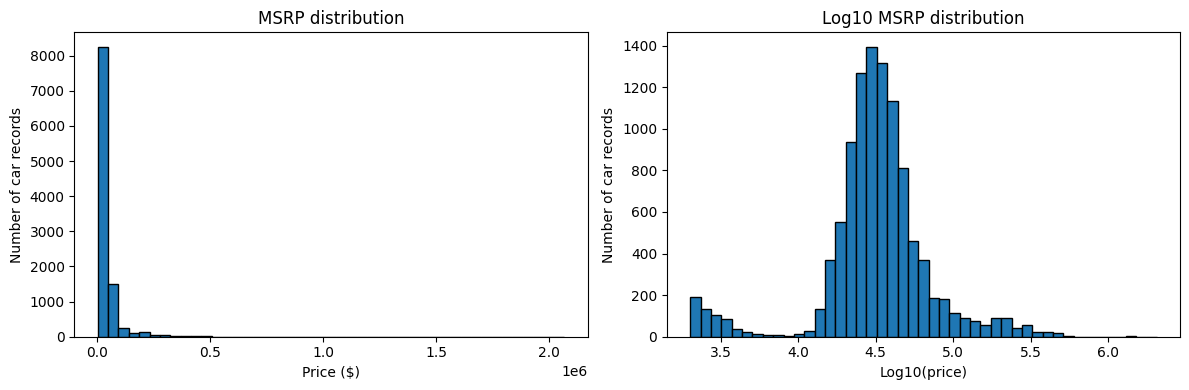

In [6]:
# Q2(a): average price, middle price
prices = clean["msrp"].dropna()
mean_price = prices.mean()
median_price = prices.median()
percent_above_mean = (prices > mean_price).mean() * 100

print("Valid prices:", len(prices))
print(f"Mean MSRP: ${mean_price:,.2f}")
print(f"Median MSRP: ${median_price:,.2f}")
print(f"Share above the mean: {percent_above_mean:.2f}%")

# Q2(b): raw MSRP and log10 MSRP
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(prices, bins=45, edgecolor="black")
axes[0].set_title("MSRP distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of car records")

axes[1].hist(np.log10(prices), bins=45, edgecolor="black")
axes[1].set_title("Log10 MSRP distribution")
axes[1].set_xlabel("Log10(price)")
axes[1].set_ylabel("Number of car records")
plt.tight_layout()
plt.show()

**Answer:** I found a mean MSRP of **$44,788.67** and a median of **$31,870** after excluding repeated $2,000 placeholder prices and exact duplicate rows. The mean is higher because very expensive luxury cars make the raw price histogram strongly right-skewed; the log-price histogram looks less skewed. Only **24.45%** of valid prices exceed the mean. I would put the **median** on the homepage because it is a better description of a typical listing when a few extreme prices raise the mean.

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [7]:
# Q3(a): use trusted MPG among 2017 cars.
cars_2017 = clean.loc[clean["year"] == 2017].copy()
size_mpg = cars_2017.groupby("vehicle_size")["highway_mpg_trusted"].agg(
    ["count", "mean", "std"]
)
display(size_mpg.round(2))

# Q3(b): standardized MPG for the two cars in the prompt
civic_z = (42 - size_mpg.loc["Compact", "mean"]) / size_mpg.loc["Compact", "std"]
volvo_z = (34 - size_mpg.loc["Large", "mean"]) / size_mpg.loc["Large", "std"]
print(f"Honda Civic z-score: {civic_z:.2f}")
print(f"Volvo S90 z-score: {volvo_z:.2f}")
print("More exceptional for its size:", "Volvo S90" if volvo_z > civic_z else "Honda Civic")

,count,mean,std
vehicle_size,,,
Compact,509,30.88,6.05
Large,468,22.99,3.49
Midsize,638,29.41,5.45


Honda Civic z-score: 1.84
Volvo S90 z-score: 3.15
More exceptional for its size: Volvo S90


**Answer:** I compared the 2017 size-class averages and found a **Honda Civic z-score of 1.84** (42 highway MPG versus about 30.88 for Compacts) and a **Volvo S90 z-score of 3.15** (34 versus about 22.99 for Large cars). Even though the Civic has higher raw MPG, I found that the **Volvo is more unusual for its class**. Both are above their size-class means, but the Volvo is over three standard deviations above its class mean.

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

Valid 2017 cars: 1624
2017 median price: $36,737.50
2017 bootstrap 95% interval: $35,940.00 to $37,682.56


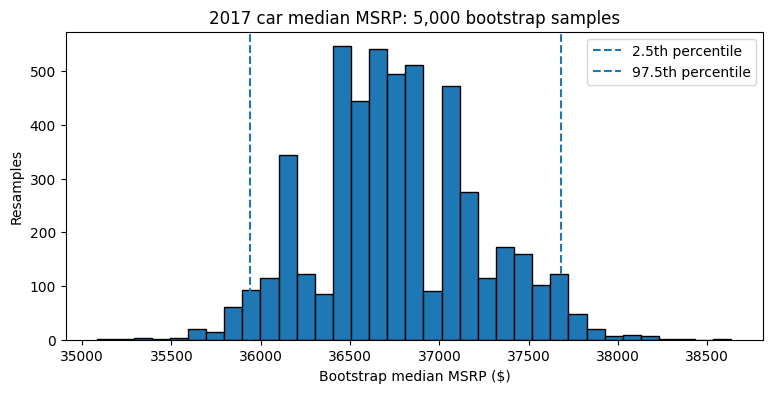

FIAT 2017 valid cars: 19
FIAT 2017 median MSRP: $23,335.00
FIAT bootstrap interval: $20,885.00 to $25,135.00
All-car interval width: $1,742.56
FIAT interval width: $4,250.00


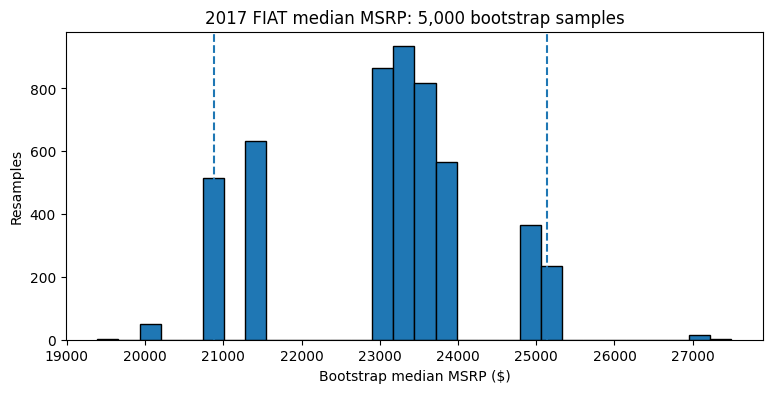

In [8]:
def bootstrap_median(values, n_boot=5000):
    # I resample with replacement and save the median every time.
    values = np.asarray(pd.Series(values).dropna(), dtype=float)
    medians = []
    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))
    return np.array(medians)

# Q4(a, b): all 2017 car prices
prices_2017 = clean.loc[clean["year"] == 2017, "msrp"].dropna()
boots_all = bootstrap_median(prices_2017)
ci_all = np.percentile(boots_all, [2.5, 97.5])
print("Valid 2017 cars:", len(prices_2017))
print(f"2017 median price: ${prices_2017.median():,.2f}")
print(f"2017 bootstrap 95% interval: ${ci_all[0]:,.2f} to ${ci_all[1]:,.2f}")

plt.figure(figsize=(9, 4))
plt.hist(boots_all, bins=35, edgecolor="black")
plt.axvline(ci_all[0], linestyle="--", label="2.5th percentile")
plt.axvline(ci_all[1], linestyle="--", label="97.5th percentile")
plt.xlabel("Bootstrap median MSRP ($)")
plt.ylabel("Resamples")
plt.title("2017 car median MSRP: 5,000 bootstrap samples")
plt.legend()
plt.show()

# Q4(c): choose FIAT, which has fewer than 50 valid 2017 records
fiat_2017 = clean.loc[
    (clean["year"] == 2017) & (clean["make"] == "FIAT"), "msrp"
].dropna()
assert len(fiat_2017) < 50
boots_fiat = bootstrap_median(fiat_2017)
ci_fiat = np.percentile(boots_fiat, [2.5, 97.5])
print("FIAT 2017 valid cars:", len(fiat_2017))
print(f"FIAT 2017 median MSRP: ${fiat_2017.median():,.2f}")
print(f"FIAT bootstrap interval: ${ci_fiat[0]:,.2f} to ${ci_fiat[1]:,.2f}")
print(f"All-car interval width: ${ci_all[1]-ci_all[0]:,.2f}")
print(f"FIAT interval width: ${ci_fiat[1]-ci_fiat[0]:,.2f}")

plt.figure(figsize=(9, 4))
plt.hist(boots_fiat, bins=30, edgecolor="black")
plt.axvline(ci_fiat[0], linestyle="--")
plt.axvline(ci_fiat[1], linestyle="--")
plt.xlabel("Bootstrap median MSRP ($)")
plt.ylabel("Resamples")
plt.title("2017 FIAT median MSRP: 5,000 bootstrap samples")
plt.show()

**Answer:** I calculated the median 2017 MSRP as **$36,737.50** from **1,624** valid car records. My 5,000 bootstrap resamples gave an approximate **95% interval of $35,940–$37,683** for the median. For **FIAT**, which has only **19** valid 2017 records, I found a median of **$23,335**, with a wider approximate interval of **$20,885–$25,135**. I would tell a manager that small changes to the set of 2017 cars could move the estimated typical price, with more uncertainty for a small brand sample; this interval does not fix nonrandom sampling bias.

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

2017 compact records: 509
Average highway MPG: 30.880
SD highway MPG: 6.045


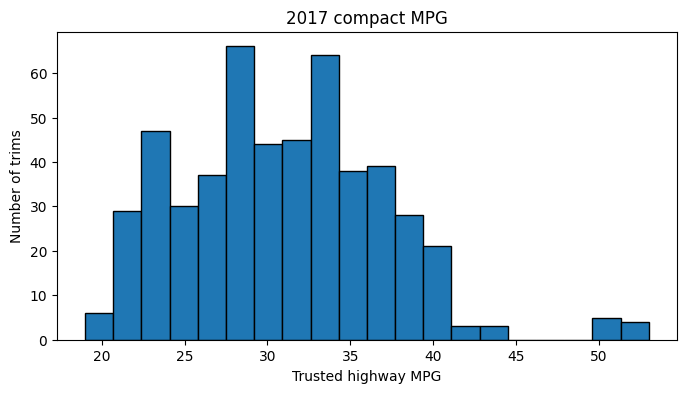

Row-level t=3.285, p=0.000546
Most repeated models:
make       model   
Toyota     Tacoma      27
Chevrolet  Corvette    24
Nissan     Frontier    22
           370Z        17
Porsche    911         14
Honda      Civic       13
Audi       A3          12
Buick      Encore      10
dtype: int64
Number of distinct make/model combinations: 85
Model-level mean MPG: 31.685
Model-level t=2.577, p=0.005851


In [9]:
# Q5(a): H0: mean 2017 compact highway MPG <= 30
#        Ha: mean 2017 compact highway MPG > 30
# I use a one-sided one-sample t-test because the claim is "over 30".
compact_2017 = clean.loc[
    (clean["year"] == 2017) & (clean["vehicle_size"] == "Compact")
].copy()
compact_mpg = compact_2017["highway_mpg_trusted"].dropna()
print("2017 compact records:", len(compact_mpg))
print(f"Average highway MPG: {compact_mpg.mean():.3f}")
print(f"SD highway MPG: {compact_mpg.std():.3f}")

plt.figure(figsize=(8, 4))
plt.hist(compact_mpg, bins=20, edgecolor="black")
plt.xlabel("Trusted highway MPG")
plt.ylabel("Number of trims")
plt.title("2017 compact MPG")
plt.show()

row_test = stats.ttest_1samp(compact_mpg, popmean=30, alternative="greater")
print(f"Row-level t={row_test.statistic:.3f}, p={row_test.pvalue:.6f}")

# Q5(d): treat each make/model as one observation instead of each trim.
model_counts = compact_2017.groupby(["make", "model"]).size().sort_values(ascending=False)
print("Most repeated models:")
print(model_counts.head(8))
model_mpg = compact_2017.groupby(["make", "model"])["highway_mpg_trusted"].mean().dropna()
model_test = stats.ttest_1samp(model_mpg, popmean=30, alternative="greater")
print("Number of distinct make/model combinations:", len(model_mpg))
print(f"Model-level mean MPG: {model_mpg.mean():.3f}")
print(f"Model-level t={model_test.statistic:.3f}, p={model_test.pvalue:.6f}")

**Answer:** I tested **H₀: mean 2017 Compact highway MPG ≤ 30** against **Hₐ: mean > 30**, using a one-sided t-test because the advertising claim is “over 30.” The **509** trusted compact records average **30.88 MPG**, with a somewhat right-skewed distribution, and the row-level test gave **p ≈ 0.00055**. I found repeated trims for many models, so I repeated the test using **85** make/model averages; the result was **31.69 MPG** and **p ≈ 0.00585**. Both tests reject the 30-MPG null at 0.05, but I trust the model-level check more because counting many versions of one model as independent cars is questionable.

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [10]:
# Q6(a): compare automatic versus manual prices.
trans = clean.loc[clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])].copy()
print("All years:")
display(trans.groupby("transmission_type").agg(
    valid_prices=("msrp", "count"),
    median_price=("msrp", "median"),
    median_year=("year", "median"),
    mean_year=("year", "mean")
).round(2))

# Q6(c): compare recent cars, then compare within size classes.
recent = trans.loc[trans["year"].between(2015, 2017)].copy()
print("2015-2017 prices:")
display(recent.groupby("transmission_type")["msrp"].agg(["count", "median"]).round(2))

print("2015-2017 median price by size and transmission:")
display(recent.pivot_table(
    index="vehicle_size", columns="transmission_type", values="msrp", aggfunc="median"
).round(2))

# Q6(c): Mann-Whitney U for 2015-2017 compact cars
recent_compacts = recent.loc[recent["vehicle_size"] == "Compact"]
auto_prices = recent_compacts.loc[recent_compacts["transmission_type"] == "AUTOMATIC", "msrp"].dropna()
manual_prices = recent_compacts.loc[recent_compacts["transmission_type"] == "MANUAL", "msrp"].dropna()
compact_test = stats.mannwhitneyu(auto_prices, manual_prices, alternative="two-sided")
print("Compact automatic count:", len(auto_prices), "manual count:", len(manual_prices))
print(f"Compact automatic median: ${auto_prices.median():,.2f}")
print(f"Compact manual median: ${manual_prices.median():,.2f}")
print(f"Mann-Whitney U={compact_test.statistic:.1f}, p={compact_test.pvalue:.5f}")

All years:


,valid_prices,median_price,median_year,mean_year
transmission_type,,,,
AUTOMATIC,7635,33620.0,2015.0,2011.84
MANUAL,2184,21875.0,2008.0,2006.48


2015-2017 prices:


,count,median
transmission_type,,
AUTOMATIC,4511,37065.0
MANUAL,813,26905.0


2015-2017 median price by size and transmission:


transmission_type,AUTOMATIC,MANUAL
vehicle_size,,
Compact,25995.0,25860.0
Large,44400.0,38395.0
Midsize,37980.0,26920.0


Compact automatic count: 1119 manual count: 589
Compact automatic median: $25,995.00
Compact manual median: $25,860.00
Mann-Whitney U=317261.0, p=0.20483


**Answer:** I found that manual cars look much cheaper overall: the median MSRP is **$21,875** for manuals versus **$33,620** for automatics, but the manual records are generally older (median model year **2008** versus **2015**). For 2015–2017 cars, the median prices are **$26,905** for manuals and **$37,065** for automatics; however, within **Compacts** the difference nearly disappears (**$25,860** manual versus **$25,995** automatic). The 2015–2017 Compact Mann–Whitney U test gives **p ≈ 0.205**, so I cannot show a clear difference in these compact price distributions. I would tell the sales rep not to recommend manuals as automatically cheaper without first comparing cars of similar age and size.

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [11]:
# Q7(a): compare 2-door versus 4-door gasoline highway MPG
with_doors = clean.loc[
    clean["number_of_doors"].isin([2, 4]) & clean["highway_mpg_trusted"].notna()
]
mpg_4 = with_doors.loc[with_doors["number_of_doors"] == 4, "highway_mpg_trusted"].to_numpy()
mpg_2 = with_doors.loc[with_doors["number_of_doors"] == 2, "highway_mpg_trusted"].to_numpy()
welch = stats.ttest_ind(mpg_4, mpg_2, equal_var=False)
mpg_difference = mpg_4.mean() - mpg_2.mean()
print("4-door sample:", len(mpg_4), "2-door sample:", len(mpg_2))
print(f"4-door mean MPG: {mpg_4.mean():.3f}")
print(f"2-door mean MPG: {mpg_2.mean():.3f}")
print(f"Difference: {mpg_difference:.3f} MPG")
print(f"Welch p-value: {welch.pvalue:.5g}")

# Q7(b): assume 12,000 highway miles and $3.50 per gallon.
miles, gas_price = 12000, 3.50
annual_cost_4 = miles * gas_price / mpg_4.mean()
annual_cost_2 = miles * gas_price / mpg_2.mean()
annual_savings = annual_cost_2 - annual_cost_4
print(f"Approximate annual fuel savings: ${annual_savings:,.2f}")

# Q7(c): repeat a 30-per-group comparison 1,000 times
# Fixed seed makes the reported fraction reproducible.
rng_sim = np.random.default_rng(123)
n_sims = 1000
hits = 0
for _ in range(n_sims):
    sample4 = rng_sim.choice(mpg_4, 30, replace=False)
    sample2 = rng_sim.choice(mpg_2, 30, replace=False)
    if stats.ttest_ind(sample4, sample2, equal_var=False).pvalue < 0.05:
        hits += 1
print(f"Significant tests: {hits} / {n_sims} = {hits/n_sims:.1%}")

4-door sample: 7897 2-door sample: 2873
4-door mean MPG: 26.805
2-door mean MPG: 25.257
Difference: 1.548 MPG
Welch p-value: 2.1056e-32
Approximate annual fuel savings: $96.05


Significant tests: 170 / 1000 = 17.0%


**Answer:** I found that 4-door cars average **26.80 highway MPG** versus **25.26 MPG** for 2-door cars, a difference of only **1.55 MPG**; the Welch test has **p ≈ 2.1 × 10⁻³²**. At 12,000 highway miles and $3.50 per gallon, that translates into approximately **$96 of annual fuel savings** for the average 4-door MPG versus the average 2-door MPG. In 1,000 simulations with just 30 cars per group, only **17.0%** of tests detected a statistically significant difference. I would not advertise that four doors *cause* fuel savings; I would say the cars in this dataset show a small average association, with other vehicle characteristics likely contributing.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo to the pricing manager**

I found that manuals have a lower overall median MSRP (**$21,875**) than automatics (**$33,620**), but that comparison is affected by the older model years in the manual group. When I limited the comparison to 2015–2017 Compact cars, the medians were nearly the same (**$25,860** manual and **$25,995** automatic), with no clear difference detected by the Mann–Whitney test (**p ≈ 0.205**). I recommend comparing prices within vehicle size and year rather than promoting every manual car as cheaper. I also found that the overall median price (**$31,870**) is much lower than the mean (**$44,789**), so I recommend the median for a typical-price headline. Finally, I would warn that the dataset includes duplicate trims, questionable $2,000 prices, and repeated models, so these comparisons are descriptive and do not prove causal effects.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

Pearson HP vs MSRP: 0.650
Pearson HP vs log10 MSRP: 0.698
Spearman HP vs MSRP: 0.822


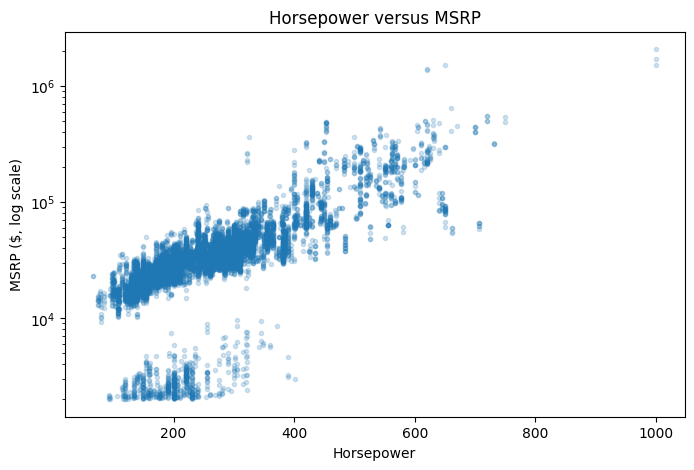

In [12]:
# S1: horsepower and price correlations
hp_data = clean[["engine_hp", "msrp"]].dropna()
hp_data = hp_data[(hp_data["engine_hp"] > 0) & (hp_data["msrp"] > 0)]
pearson = hp_data["engine_hp"].corr(hp_data["msrp"])
pearson_log = hp_data["engine_hp"].corr(np.log10(hp_data["msrp"]))
spearman = hp_data["engine_hp"].corr(hp_data["msrp"], method="spearman")
print(f"Pearson HP vs MSRP: {pearson:.3f}")
print(f"Pearson HP vs log10 MSRP: {pearson_log:.3f}")
print(f"Spearman HP vs MSRP: {spearman:.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(hp_data["engine_hp"], hp_data["msrp"], alpha=0.2, s=9)
plt.yscale("log")
plt.xlabel("Horsepower")
plt.ylabel("MSRP ($, log scale)")
plt.title("Horsepower versus MSRP")
plt.show()

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [13]:
# S2: vehicle size and transmission association, 2015-2017
s2 = recent.dropna(subset=["vehicle_size"])
ct = pd.crosstab(s2["vehicle_size"], s2["transmission_type"])
display(ct)
chi2, chi_p, dof, expected = stats.chi2_contingency(ct)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {chi_p:.3g}")
print(f"Smallest expected cell count: {expected.min():.2f}")

transmission_type,AUTOMATIC,MANUAL
vehicle_size,,
Compact,1119,589
Large,1473,26
Midsize,1919,198


Chi-square statistic: 756.929
Degrees of freedom: 2
p-value: 4.31e-165
Smallest expected cell count: 228.90


### Optional stretch interpretations

**S1:** I found a positive horsepower–price association: Pearson **0.650** for raw MSRP, Pearson **0.698** for log MSRP, and Spearman **0.822**. I think the values differ because extreme prices and nonlinear relationships affect the methods differently. More horsepower does not automatically *cause* higher prices; luxury branding and vehicle type could influence both.

**S2:** I found a strong association between vehicle size and transmission for 2015–2017 vehicles (χ² ≈ **756.9**, p **< 0.001**). The share of manual trims is much higher among Compacts than Large vehicles, which is another reason overall manual-versus-automatic price comparisons can be misleading.